In [221]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.stats import chi2, f

sys.path.insert(0, str(Path.cwd().parent))


from utils.bivaraite_boxplot import plot_segmented_boxplot
from utils.cat_num_dep import hub_pruebas_num_cat
from utils.fancy_barplot import fancy_bars

In [157]:
df = pd.read_csv("../data/datos_inmobiliarios_clean.csv")

In [158]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price_amount,20442.0,9.225929e+08,7.068752e+08,4.563243e+07,3.850000e+08,7.000000e+08,1.250000e+09,4.000000e+09
admin_fee,20442.0,6.436422e+05,5.809841e+05,1.000000e+00,2.100000e+05,4.500000e+05,8.900000e+05,3.320868e+06
price_per_m2,20442.0,6.368347e+06,2.570859e+06,4.563243e+05,4.633537e+06,5.961458e+06,7.766077e+06,1.754167e+07
area_built_m2,20442.0,1.667646e+02,1.413496e+02,1.400000e+01,6.200000e+01,1.200000e+02,2.327413e+02,8.000000e+02
area_private_m2,20442.0,1.641769e+02,1.402123e+02,1.102000e+01,6.000000e+01,1.186014e+02,2.276464e+02,7.865520e+02
bedrooms,20442.0,3.375844e+00,2.003805e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,20442.0,2.878437e+00,1.524692e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,2.000000e+01
parking_spaces,20442.0,1.895216e+00,1.729345e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00,1.270000e+02
stratum,20442.0,4.226886e+00,1.222510e+00,1.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00
floor,20442.0,4.188827e+00,3.641452e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,3.500000e+01


In [159]:
int(7.000000e+08)

700000000

# Distribuciones conjuntas e inferencia multivariada

El EDA y preparación de datos ya se encuentra en los demas cuadernos que fueron entregados en la oportunidad anterior.

## 3. Inferencia multivariada sobre el vector de medias.

### Crear vector de medias para las variables:

* Admin Fee
* Log Price Amount

In [160]:
zbar = (df['admin_fee'].mean(), df['log_price_amount'].mean())
cov = np.cov(df['admin_fee'], df['log_price_amount'])

zbar

(np.float64(643642.2025492614), np.float64(20.36917180942848))

In [161]:
np.sqrt(cov[0][0])

np.float64(580984.0917164125)

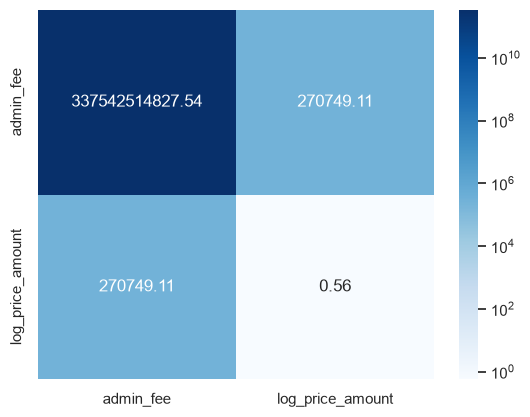

In [162]:
sns.heatmap(
    cov,
    annot=True,
    fmt=".2f",
    cmap='Blues',  # Usas el mapa creado
    norm=LogNorm(),
    xticklabels=['admin_fee', 'log_price_amount'],
    yticklabels=['admin_fee', 'log_price_amount']
)

plt.show()

El vector muestra que la tarifa de administración promedio ronda los 643,642.20 COP mientras que el precio promedio (transformado con un logaritmo base 10) ronda los 20.3692 log COP.

La matriz de covarianzas da información sobre como se asocian las variables (diagonal secundaria) y que tan dispersas estan estas mismas (diagonal principal), siendo la cuota de administración la mas variable de las 2 con una varianza de $S^2 = 337542514827.54$, es decir que su desviacion estandar es $S = 580,984.09$ COP, constituyendo una variabilidad considerble respecto a la media y a la unidad de variable. Por otro lado el precio es muy poco variable, esto gracias a la transformación logaritmica que se realizó anteriormente y por ultimo la asociación entre estas 2 es positivas indicando de esta manera que mientras mas alto sea el precio del inmueble mayor será su cuota de administración.

### Definir $\mu_0$

segun Jurgen D. Toloza Delgado la media del precio de venta de los inmuebles de Bogota es de 464.598.900 y segun El tiempo la cuota de administracion media es de 190.000 pesos al mes

Por esto se define $\mu_0$ como:

$$
\begin{aligned}
\mu_0 = \begin{pmatrix} 190.000 \\ \ln(464.598.900) \end{pmatrix}
\end{aligned}
$$

- https://doi.org/10.17230/ingciencia.17.34.2
- https://www.eltiempo.com/economia/sectores/propiedad-horizontal-los-vacios-que-le-cuestan-millones-al-fisco-655558


In [163]:
mu_0 = np.array([190_000, np.log(464_598_000)])

mu_0


array([1.90000000e+05, 1.99566831e+01])

### Formular hipotesis

$$
\begin{aligned}
H_0 &: \text{El vector de medias real sigue lo que indica la literatura, } \boldsymbol{\mu} = \boldsymbol{\mu}_0 \\
H_1 &: \text{El vector de medias real difiere de lo indicado por la literatura, } \boldsymbol{\mu} \neq \boldsymbol{\mu}_0
\end{aligned}
$$

Se usa el caso donde no se conoce $\Sigma$



### Calcular la distancia de Mahalanobis

In [164]:
def mahalanobis_dist(df, colx, coly, x_mean_0, y_mean_0):


    Sigma = np.cov(df[colx], df[coly])
    Sigma_inv = np.linalg.inv(Sigma)

    mu = np.array([x_mean_0, y_mean_0])
    z = df[[colx, coly]].mean().to_numpy()

    diferencia = z - mu

    D2_punto = diferencia @ Sigma_inv @ diferencia
    D_punto = np.sqrt(D2_punto)

    return {
            'D2 (distancia cuadrada)': D2_punto,
            'D (distancia mahalanobis)': D_punto
        }

In [165]:
distancia_vectores = mahalanobis_dist(df=df,
    colx='admin_fee',
    coly='log_price_amount',
    x_mean_0=mu_0[0],
    y_mean_0=mu_0[1])

distancia_vectores

{'D2 (distancia cuadrada)': np.float64(0.6165357753942625),
 'D (distancia mahalanobis)': np.float64(0.7851979211601764)}

La baja distancia de mahalanobis indica que la media muestral y el vector de medias que se quiere probar como cierto es realmente baja, inclusive considerando la asociación de las variables, no obstante para determinar la similitud estadistica falta realizar el calculo del estadistico de prueba y su p-valor.

### construir una region de confianza conjunta para $\mu$ 
se supone $\alpha = 0.05$ 
    $$ \mathcal C_{0.95}
    =
    \left\{
    \boldsymbol{\mu}:
    n(\bar{\mathbf Z}-\boldsymbol{\mu})^\top
    \Sigma^{-1}
    (\bar{\mathbf Z}-\boldsymbol{\mu})
    \le
    \chi^2_{2,0.95}
    \right\}. $$

In [166]:
distancia_vectores['D2 (distancia cuadrada)'] * df.shape[0]

np.float64(12603.224320609514)

In [167]:
chi2.ppf(0.95, df=2)

np.float64(5.991464547107979)

Luego la region de confianza conjunta es: 
$$\mathcal C_{0.95} =
\left\{
\boldsymbol{\mu}:
n(\bar{\mathbf Z}-\boldsymbol{\mu})^\top
\Sigma^{-1}
(\bar{\mathbf Z}-\boldsymbol{\mu})
\le
5.99
\right\}.
$$
La cual al contrastarla con la distancia cuadrada por n resulta en:

$$T^2_{obs} = n(\bar{\mathbf{Z}} - \boldsymbol{\mu}_0)^\top \boldsymbol{\Sigma}^{-1} (\bar{\mathbf{Z}} - \boldsymbol{\mu}_0) = 20320.33$$

ya que $20320.33 > 5.991$
> Note que la distancia cuadrada por n no cumple con la condicion de esa region de confianza. Es decir el vector no pertenece a la region de confianza, por lo cual se rechaza $H_0: \boldsymbol{\mu} = \boldsymbol{\mu}_0$

### realizar la prueba de hipotesis multivariada correspondiente y reportar estadistico, distribucion, p-valor, decision e interpretacion en contexto.

In [168]:
def T2_test(df, colx, coly, x_mean_0, y_mean_0):
    n = len(df)
    p = 2  # Caso bivariado

    # Matriz de covarianza y su inversa
    Sigma = np.cov(df[colx], df[coly])
    Sigma_inv = np.linalg.inv(Sigma)

    # Vectores de medias
    mu_0 = np.array([x_mean_0, y_mean_0])
    z = df[[colx, coly]].mean().to_numpy()

    # Distancia de Mahalanobis cuadrada
    diferencia = z - mu_0
    D2 = diferencia @ Sigma_inv @ diferencia
    D = np.sqrt(D2)

    # Estadístico Hotelling T^2 y transformación a F
    T2 = n * D2
    F_stat = ((n - p) / (p * (n - 1))) * T2

    # p-valor usando la distribución F
    p_value = f.sf(F_stat, dfn=p, dfd=n - p)

    return {
        'n': n,
        'p': p,
        'Sigma': Sigma,
        'Sigma_inv': Sigma_inv,
        'mu_0': mu_0,
        'z': z,
        'diferencia': diferencia,
        'D2 (distancia cuadrada)': float(D2),
        'D (distancia Mahalanobis)': float(D),
        'Hotelling T2': float(T2),
        'Estadistico F': float(F_stat),
        'p-valor': float(p_value)
    }

In [169]:
T2_test(df=df,
    colx='admin_fee',
    coly='log_price_amount',
    x_mean_0=mu_0[0],
    y_mean_0=mu_0[1])

{'n': 20442,
 'p': 2,
 'Sigma': array([[3.37542515e+11, 2.70749107e+05],
        [2.70749107e+05, 5.61642463e-01]]),
 'Sigma_inv': array([[ 4.83037192e-12, -2.32856126e-06],
        [-2.32856126e-06,  2.90301391e+00]]),
 'mu_0': array([1.90000000e+05, 1.99566831e+01]),
 'z': array([6.43642203e+05, 2.03691718e+01]),
 'diferencia': array([4.53642203e+05, 4.12488736e-01]),
 'D2 (distancia cuadrada)': 0.6165357753942625,
 'D (distancia Mahalanobis)': 0.7851979211601764,
 'Hotelling T2': 12603.224320609514,
 'Estadistico F': 6301.303877336199,
 'p-valor': 0.0}

Si bien en un primer momento la baja distancia lucia como un buen indicio de no rechazo, al definir la region de confianza y calcular el estadistico F y el valor p se determina que existe la suficiente evidencia estadistica para rechazar la hipotesis nula.

Por lo tanto la media poblacional no coincide con $\mu_0$, es decir los log precios y las tarifas de administracion reales difieren de $$ \begin{aligned} \mu_0 = \begin{pmatrix} 190.000 \\ \ln(464.598.900) \end{pmatrix}
\end{aligned} $$

## 4. Interpretación grafica.

In [170]:
def confidence_ellipse_from_cov(mean, cov, level=0.95, ax=None, label=None, **kwargs):
    if ax is None:
        ax = plt.gca()

    c2 = chi2.ppf(level, df=2)

    eigvals, eigvecs = np.linalg.eigh(cov)
    order = eigvals.argsort()[::-1]
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    width = 2 * np.sqrt(c2 * eigvals[0])
    height = 2 * np.sqrt(c2 * eigvals[1])

    angle = np.degrees(np.arctan2(*eigvecs[:, 0][::-1]))

    kwargs.setdefault("fill", False)
    ell = Ellipse(
        xy=mean, width=width, height=height, angle=angle,
        label=label, **kwargs
    )
    ax.add_patch(ell)
    return ell

def plot_multivariate_test_decision(df, colx, coly, x_mean_0, y_mean_0, alpha=0.05):
    """
    Función para visualizar la decisión del test multivariado y mostrar el resumen analítico.
    """
    # 1. Llamar a la función T2_test para obtener todos los cálculos
    res = T2_test(df, colx, coly, x_mean_0, y_mean_0)

    n = res['n']
    p = res['p']
    Sigma = res['Sigma']
    Sigma_inv = res['Sigma_inv']
    mu0 = res['mu_0']
    xbar = res['z']
    d = res['diferencia']
    D2 = res['D2 (distancia cuadrada)']

    # Usaremos el estadístico T equivalente del enfoque asintótico/chi-cuadrado para la región visual o el chi2 de referencia
    T = res['Hotelling T2'] # O n * D2
    crit = chi2.ppf(1 - alpha, df=p)
    p_value_chi2 = chi2.sf(T, df=p)
    rechaza = T > crit

    # 2. Figura: vista general + zoom sobre la región de confianza
    nivel = f"{1 - alpha:.0%}"
    # Semiancho y semialto de la región, y qué tan lejos queda mu0 de ella
    half = np.sqrt(crit * np.diag(Sigma) / n)
    ratio = np.max(np.abs(d) / half)
    mu0_en_zoom = ratio < 4
    pad = max(1.8, 1.25 * ratio) if mu0_en_zoom else 1.8

    # Tema y colores del proyecto
    sns.set_theme(style="white", font="sans-serif")
    color_media, color_region = sns.color_palette("mako", 2)
    color_mu0 = "#ec7063"

    fig, (ax, ax_zoom) = plt.subplots(1, 2, figsize=(15, 6.5), dpi=120)

    for a in (ax, ax_zoom):
        a.scatter(
            df[colx],
            df[coly],
            s=6,
            alpha=0.25,
            color="#94a3b8",
            rasterized=True,
            label="Observaciones muestrales"
        )
        a.plot(
            [mu0[0], xbar[0]],
            [mu0[1], xbar[1]],
            linestyle="--",
            linewidth=1.5,
            color="#475569",
            label=r"Vector $\bar{Z}-\mu_0$"
        )
        confidence_ellipse_from_cov(
            mean=xbar,
            cov=Sigma / n,
            level=1 - alpha,
            ax=a,
            fill=True,
            facecolor=(color_region, 0.25),
            edgecolor=color_region,
            linewidth=2,
            label=f"Región conjunta de confianza {nivel}"
        )
        a.scatter(
            [xbar[0]],
            [xbar[1]],
            s=70,
            color=color_media,
            edgecolor="white",
            zorder=3,
            label=r"Media muestral $\bar{Z}$"
        )
        a.scatter(
            [mu0[0]],
            [mu0[1]],
            marker="x",
            s=160,
            linewidths=3,
            color=color_mu0,
            zorder=3,
            label=r"Valor bajo $H_0$: $\mu_0$"
        )
        a.annotate(
            r"$\bar{Z}$",
            xy=xbar,
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=12,
            color="#1e293b"
        )
        a.annotate(
            r"$\mu_0$",
            xy=mu0,
            xytext=(8, -14),
            textcoords="offset points",
            fontsize=12,
            color="#1e293b"
        )
        a.set_xlabel(
            colx, fontsize=11, fontweight="bold", color="#475569", labelpad=10
        )
        a.set_ylabel(
            coly, fontsize=11, fontweight="bold", color="#475569", labelpad=10
        )
        a.xaxis.set_major_formatter("{x:,.10g}")
        a.yaxis.set_major_formatter("{x:,.10g}")
        a.grid(True, linestyle="--", alpha=0.3, color="#94a3b8")
        a.set_axisbelow(True)

    sns.despine(fig=fig, top=True, right=True)

    # 3. Zoom centrado en la media muestral
    ax_zoom.set_xlim(xbar[0] - pad * half[0], xbar[0] + pad * half[0])
    ax_zoom.set_ylim(xbar[1] - pad * half[1], xbar[1] + pad * half[1])
    ax.indicate_inset_zoom(ax_zoom, edgecolor="#475569")

    if not mu0_en_zoom:
        # mu0 no cabe en el zoom: flecha en su dirección, con la etiqueta
        # más allá de la punta y a un lado del vector, lejos de la región
        punta = xbar - 0.75 * pad * d / ratio
        ax_zoom.annotate(
            "",
            xy=punta,
            xytext=xbar,
            arrowprops={"arrowstyle": "->", "color": color_mu0}
        )
        ax_zoom.annotate(
            r"hacia $\mu_0$",
            xy=punta,
            xytext=(-6 * np.sign(d[0]), 6 * np.sign(d[1])),
            textcoords="offset points",
            ha="right" if d[0] > 0 else "left",
            va="bottom" if d[1] > 0 else "top",
            color=color_mu0
        )

    # 4. Títulos y leyenda
    ax.set_title(
        "Vista general",
        fontsize=12, fontweight="bold", loc="left", color="#1e293b", pad=12
    )
    ax_zoom.set_title(
        f"Zoom: región de confianza del {nivel}",
        fontsize=12, fontweight="bold", loc="left", color="#1e293b", pad=12
    )

    if rechaza:
        donde = (
            f"fuera de la región {nivel} ({np.sqrt(T / crit):.3g} veces más"
            r" lejos de $\bar{Z}$ que su borde)"
        )
        decision = "se rechaza"
    else:
        donde = f"dentro de la región {nivel}"
        decision = "no se rechaza"
    fig.suptitle(
        "Relación entre región de confianza y prueba de hipótesis\n"
        rf"$\mu_0$ queda {donde}  $\Rightarrow$  {decision} $H_0$",
        fontsize=14, fontweight="bold", color="#1e293b", x=0.05, ha="left"
    )
    fig.legend(
        *ax.get_legend_handles_labels(),
        loc="lower center",
        ncol=5,
        frameon=False
    )
    fig.tight_layout(rect=(0, 0.06, 1, 1))

    plt.show()

    # 6. Resumen numérico en consola
    print("=" * 70)
    print("PRUEBA DE HIPÓTESIS MULTIVARIADA (HOTELLING / T²)")
    print("=" * 70)

    print("\nHipótesis:")
    print("H0: μ = μ0")
    print("H1: μ ≠ μ0")

    print("\nValor bajo H0:")
    print("μ0 =", np.round(mu0, 4))

    print("\nMedia muestral:")
    print("Z̄ =", np.round(xbar, 4))

    print("\nDiferencia:")
    print("Z̄ - μ0 =", np.round(d, 4))

    print("\nMuestras (n):", n)
    print("\nMatriz de covarianzas Σ:")
    print(np.round(Sigma, 4))

    print("\nInversa Σ⁻¹:")
    print(np.round(Sigma_inv, 4))

    print("\n" + "-" * 75)
    print("RESULTADOS DE LA FUNCIÓN T2_test")
    print("-" * 75)
    for k, v in res.items():
        if isinstance(v, np.ndarray):
            print(f"{k}:\n{np.round(v, 4)}")
        else:
            print(f"{k}: {v}")

    print("\n" + "-" * 70)
    print("DECISIÓN")
    print("-" * 70)
    if rechaza:
        print(f"\nDECISIÓN: RECHAZAR H0 al nivel α = {alpha}.")
        print("Geométricamente, μ0 está fuera de la región conjunta de confianza del 95%.")
    else:
        print(f"\nDECISIÓN: NO RECHAZAR H0 al nivel α = {alpha}.")
        print("Geométricamente, μ0 está dentro de la región conjunta de confianza del 95%.")

    print("=" * 70)

    return res

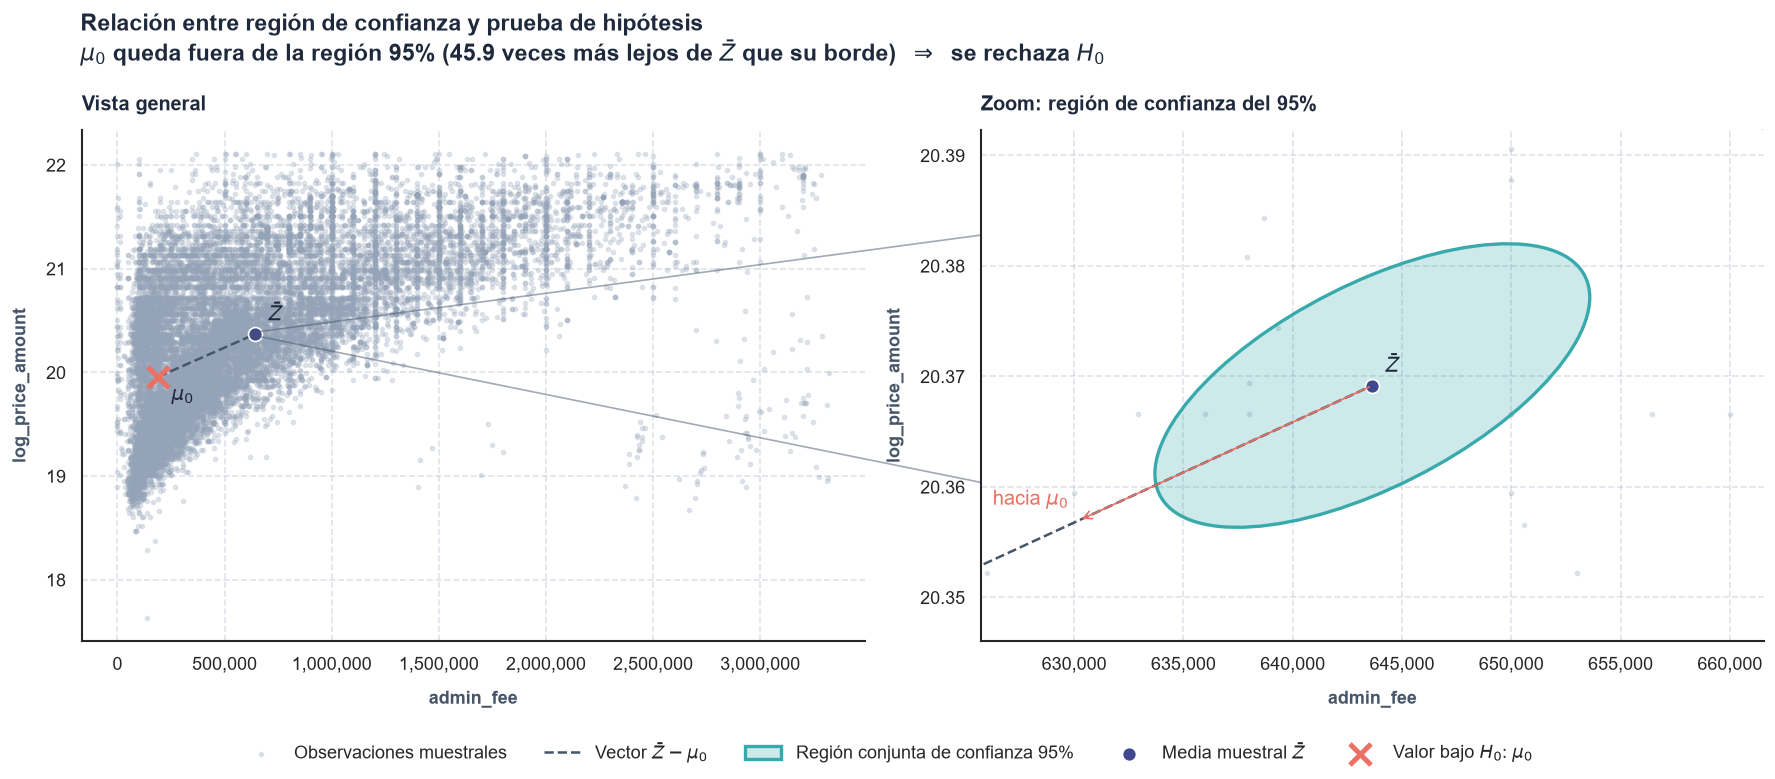

PRUEBA DE HIPÓTESIS MULTIVARIADA (HOTELLING / T²)

Hipótesis:
H0: μ = μ0
H1: μ ≠ μ0

Valor bajo H0:
μ0 = [1.90000e+05 1.99567e+01]

Media muestral:
Z̄ = [6.43642203e+05 2.03692000e+01]

Diferencia:
Z̄ - μ0 = [4.53642203e+05 4.12500000e-01]

Muestras (n): 20442

Matriz de covarianzas Σ:
[[3.37542515e+11 2.70749107e+05]
 [2.70749107e+05 5.61600000e-01]]

Inversa Σ⁻¹:
[[ 0.    -0.   ]
 [-0.     2.903]]

---------------------------------------------------------------------------
RESULTADOS DE LA FUNCIÓN T2_test
---------------------------------------------------------------------------
n: 20442
p: 2
Sigma:
[[3.37542515e+11 2.70749107e+05]
 [2.70749107e+05 5.61600000e-01]]
Sigma_inv:
[[ 0.    -0.   ]
 [-0.     2.903]]
mu_0:
[1.90000e+05 1.99567e+01]
z:
[6.43642203e+05 2.03692000e+01]
diferencia:
[4.53642203e+05 4.12500000e-01]
D2 (distancia cuadrada): 0.6165357753942625
D (distancia Mahalanobis): 0.7851979211601764
Hotelling T2: 12603.224320609514
Estadistico F: 6301.303877336199
p-valor: 0

{'n': 20442,
 'p': 2,
 'Sigma': array([[3.37542515e+11, 2.70749107e+05],
        [2.70749107e+05, 5.61642463e-01]]),
 'Sigma_inv': array([[ 4.83037192e-12, -2.32856126e-06],
        [-2.32856126e-06,  2.90301391e+00]]),
 'mu_0': array([1.90000000e+05, 1.99566831e+01]),
 'z': array([6.43642203e+05, 2.03691718e+01]),
 'diferencia': array([4.53642203e+05, 4.12488736e-01]),
 'D2 (distancia cuadrada)': 0.6165357753942625,
 'D (distancia Mahalanobis)': 0.7851979211601764,
 'Hotelling T2': 12603.224320609514,
 'Estadistico F': 6301.303877336199,
 'p-valor': 0.0}

In [171]:
plot_multivariate_test_decision(df=df,
    colx='admin_fee',
    coly='log_price_amount',
    x_mean_0=mu_0[0],
    y_mean_0=mu_0[1])

In [172]:
int(6.43642203e+05), int(9.22592927e+08)

(643642, 922592927)

Ya que $\mu_0$ esta fuera de la region de confianza se rechaza la hipotesis nula, esto respalda de manera grafica y geometrica la desición que se toma con el p value al 95% de confianza.

## 5. Comparación multivariada entre dos grupos

### Definir grupos

Se compararán tres parejas de grupos y las variables cuantitativas a comparar serán `log_price_amount` y `area_built_m2`.

Esta comparación se jusrifica bajo los hallazgos del cuaderno bicariate_eda, que se recuperan a continuación. Donde se logra ver que el precio de las viviendas difiere segun el territorio, especialmente chia. A esto se le suma que en el contexto inmoviliario muchas veces los precios y el metraje de los inmuebles cambia segun la zona.

Ademas se suma el analisis al cambio de `area_built_m2` que de nuevo muestra que chia es donde se ve un mayor cambio respecto a los demas.

Ya que la variabilidad difiere entre grupos se opto por investigar y se econtro que en lugar de usar $S_p$ se usa:

$$S_{diff} = \frac{S_1}{n_1} + \frac{S_2}{n_2}$$
Sin embargo se mostrara el resultado usando los dos procedimientos con el fin de contrastar.

Esto es analogo a utilizar una diferencia de varianzas en el caso univariado donde

$$\text{Var}(\bar{X}_1 - \bar{X}_2) = \text{Var}(\bar{X}_1) + \text{Var}(\bar{X}_2) = \frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}$$

De ahí se extrapola al caso multivariado de esta manera:

- La matriz de covarianza de un vector de media muestral $\mathbf{\bar{Z}}_1$ es $\frac{1}{n_1}\Sigma_1$.

- La matriz de covarianza del vector de media muestral $\mathbf{\bar{Z}}_2$ es $\frac{1}{n_2}\Sigma_2$.

y suponiendo independencia entre las observaciones de los grupos se tiene

$$\text{Cov}(\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2) = \text{Cov}(\mathbf{\bar{Z}}_1) + \text{Cov}(\mathbf{\bar{Z}}_2) = \frac{\Sigma_1}{n_1} + \frac{\Sigma_2}{n_2}$$

o en el caso muestral tambien
$$\frac{S_1}{n_1} + \frac{S_2}{n_2}$$

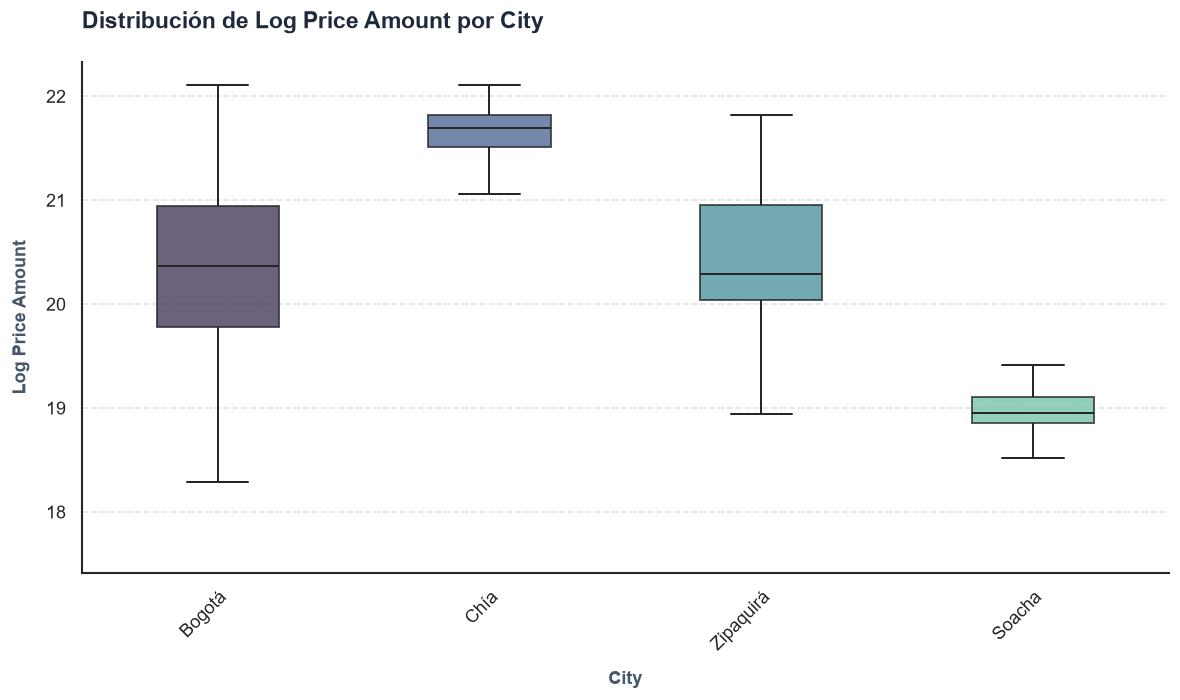

In [ ]:
plot_segmented_boxplot(df, "log_price_amount", "city", show_points=False)

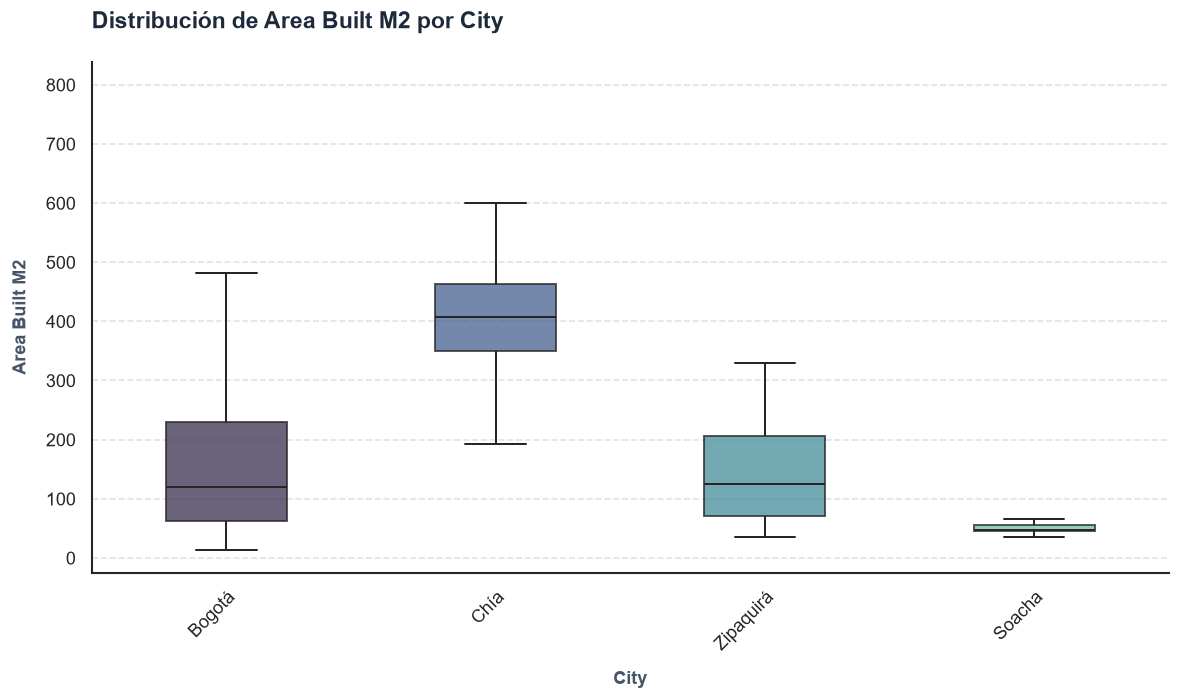

In [174]:
plot_segmented_boxplot(df, "area_built_m2", "city", show_points=False)

In [175]:
hub_pruebas_num_cat(df, "log_price_amount", ["city"])

,var_numerica,var_categorica,n_grupos,prueba,estadistico,p_valor,normalidad,homocedasticidad,decision,conclusion,post_hoc
0,log_price_amount,city,4,Kruskal-Wallis (H),823.5286,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,Bogotá vs Chía (p=0.0000); Bogotá vs Soacha (p...


In [176]:
hub_pruebas_num_cat(df, "area_built_m2", ["city"])

,var_numerica,var_categorica,n_grupos,prueba,estadistico,p_valor,normalidad,homocedasticidad,decision,conclusion,post_hoc
0,area_built_m2,city,4,Kruskal-Wallis (H),561.4555,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,Bogotá vs Chía (p=0.0000); Bogotá vs Soacha (p...


#### Viviendas de Bogotá v.s viviendas de Chia

In [231]:
def hotteling_comparison(df1, df2, colx, coly, alpha=0.05):
    p = 2  # Caso bivariado
    z_1 = df1[[colx, coly]].mean().to_numpy()
    z_2 = df2[[colx, coly]].mean().to_numpy()

    cov1 = df1[[colx, coly]].cov().to_numpy()
    cov2 = df2[[colx, coly]].cov().to_numpy()

    cov_ig = np.allclose(cov1, cov2, rtol=1e-4, atol=1e-6)

    S_diff = cov1 / len(df1) + cov2 / len(df2)
    S_pooled = ((len(df1) - 1) * cov1 + (len(df2) - 1) * cov2) / (len(df1) + len(df2) - 2)

    Z = z_1 - z_2
    # Usar la matriz para vars diferentes
    T2_diff = Z.T @ np.linalg.inv(S_diff) @ Z

    F_stat_diff = ((len(df1) + len(df2) - p - 1) / (p * (len(df1) + len(df2) - 1))) * T2_diff

    p_value_diff = f.sf(F_stat_diff, dfn=p, dfd=len(df1) + len(df2) - p - 1)

    reject_null_diff = p_value_diff < alpha

    # usar la matriz de covarianza común suponemos que son iguales (caso de comparasion teorica)
    S_pooled_scaled = S_pooled * (1 / len(df1) + 1 / len(df2))
    T2_pooled = Z.T @ np.linalg.inv(S_pooled_scaled) @ Z

    F_stat_pooled = ((len(df1) + len(df2) - p - 1) / (p * (len(df1) + len(df2) - 1))) * T2_pooled

    p_value_pooled = f.sf(F_stat_pooled, dfn=p, dfd=len(df1) + len(df2) - p - 1)

    reject_null_pooled = p_value_pooled < alpha

    return {
        'z_1': z_1,
        'z_2': z_2,
        'cov1': cov1,
        'cov2': cov2,
        'matriz de covarianzas comun': cov_ig,
        'S_diff': S_diff,
        'S_pooled': S_pooled,
        'Z': Z,
        'T2_diff': T2_diff,
        'F_stat_diff': F_stat_diff,
        'p_value_diff': p_value_diff,
        'reject_null_diff': reject_null_diff,
        'T2_pooled': T2_pooled,
        'F_stat_pooled': F_stat_pooled,
        'p_value_pooled': p_value_pooled,
        'reject_null_pooled': reject_null_pooled,
    }


In [178]:
df_bogota = df[df['city'] == 'Bogotá'].copy()
df_chia = df[df['city'] == 'Chía'].copy()

In [179]:
def plot_group_comparison(df1, df2, label1='Bogotá', label2='Chía', x='area_built_m2', y='log_price_amount'):
    # Unir ambos DataFrames para facilitar el gráfico conjunto con Seaborn
    df1 = df1.copy()
    df2 = df2.copy()
    df1['grupo'] = label1
    df2['grupo'] = label2
    df_combined = pd.concat([df1, df2], ignore_index=True)

    # Calcular métricas para el recuadro (Covarianza cruzada y Correlación de Pearson)
    # cov(x, y) de la matriz de covarianza devuelta por .cov() en la posición [0, 1]
    cov1 = df1[[x, y]].cov().iloc[0, 1]
    corr1 = df1[[x, y]].corr().iloc[0, 1]

    cov2 = df2[[x, y]].cov().iloc[0, 1]
    corr2 = df2[[x, y]].corr().iloc[0, 1]

    # Configurar la figura (tema y paleta del proyecto)
    sns.set_theme(style='white', font='sans-serif')
    color1, color2 = sns.color_palette('mako', 2)
    plt.figure(figsize=(10, 6), dpi=120)

    # Crear scatter plot con líneas de tendencia (regplot o lmplot integrado en scatterplot con hue)
    sns.scatterplot(
        data=df_combined,
        x=x,
        y=y,
        hue='grupo',
        alpha=0.5,
        s=18,
        linewidth=0,
        palette={label1: color1, label2: color2}
    )

    # Añadir líneas de tendencia (regresión lineal) por separado para cada grupo
    sns.regplot(
        data=df1, x=x, y=y, scatter=False, color=color1,
        line_kws={'linestyle': '--', 'linewidth': 2}
    )
    sns.regplot(
        data=df2, x=x, y=y, scatter=False, color=color2,
        line_kws={'linestyle': '--', 'linewidth': 2}
    )

    # Texto descriptivo con las métricas (recuadro)
    texto_stats = (
        f"--- {label1} ---\n"
        f"Cov: {cov1:,.2f}\n"
        f"Corr: {corr1:.3f}\n\n"
        f"--- {label2} ---\n"
        f"Cov: {cov2:,.2f}\n"
        f"Corr: {corr2:.3f}"
    )

    # Añadir caja de texto en la esquina superior izquierda del gráfico
    plt.gca().text(
        0.05, 0.95, texto_stats,
        transform=plt.gca().transAxes,
        fontsize=10,
        color='#1e293b',
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='#94a3b8')
    )

    # Personalización de títulos y ejes
    plt.title(
        f'Comparación de Tendencias y Variación Mutua: {label1} vs {label2}',
        fontsize=14, fontweight='bold', pad=20, loc='left', color='#1e293b'
    )
    plt.xlabel(
        'Área Construida (m²)',
        fontsize=11, fontweight='bold', color='#475569', labelpad=10
    )
    plt.ylabel(
        'Precio (COP)',
        fontsize=11, fontweight='bold', color='#475569', labelpad=10
    )
    plt.legend(title='Grupos', frameon=False)
    plt.grid(True, linestyle='--', alpha=0.3, color='#94a3b8')
    plt.gca().set_axisbelow(True)
    sns.despine(top=True, right=True)
    plt.tight_layout()
    plt.show()

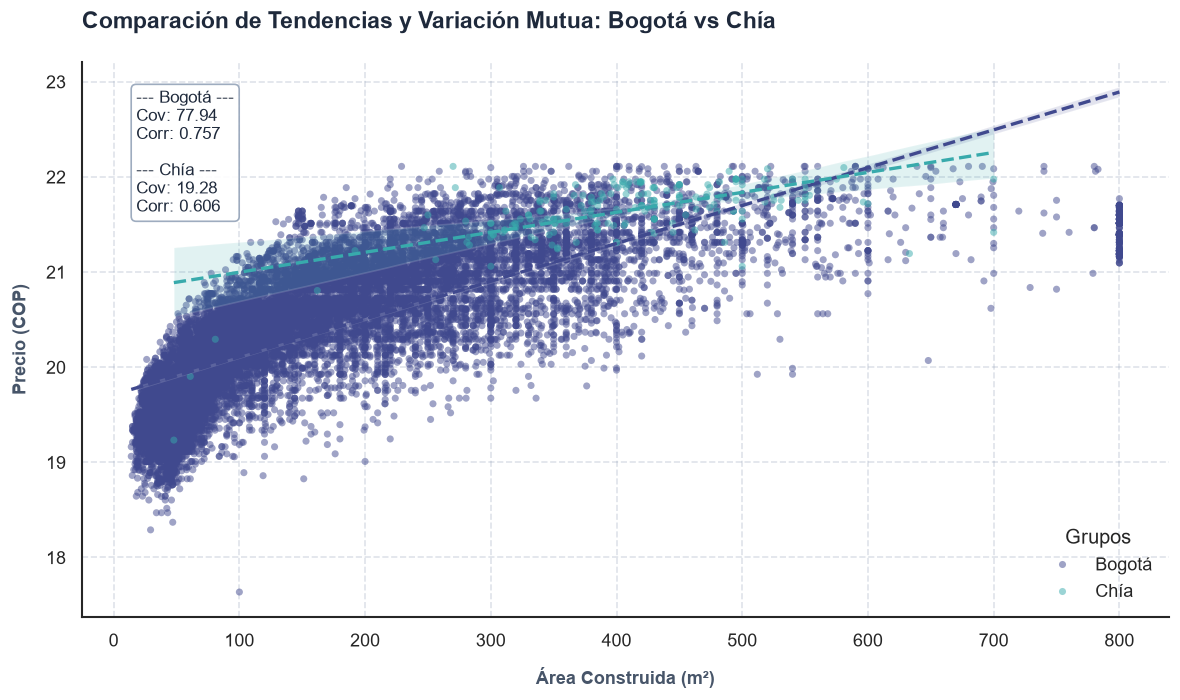

In [180]:
plot_group_comparison(df_bogota, df_chia, label1='Bogotá', label2='Chía')

Note como la covarianza y la correlacion cambia de grupo a grupo, esto sugiere que el mejor metodo es aquel que no asume que comparten la misma matriz de covarianzas.

In [181]:
resultados_1 = hotteling_comparison(df_bogota, df_chia, 'area_built_m2', 'log_price_amount')
resultados_1

{'z_1': array([165.37171486,  20.36740647]),
 'z_2': array([406.26034973,  21.63971404]),
 'cov1': array([[1.95976037e+04, 7.79376490e+01],
        [7.79376490e+01, 5.40814868e-01]]),
 'cov2': array([[9.19229375e+03, 1.92834392e+01],
        [1.92834392e+01, 1.10173938e-01]]),
 'matriz de covarianzas comun': False,
 'S_diff': array([[5.01318988e+01, 1.06998455e-01],
        [1.06998455e-01, 6.16078349e-04]]),
 'S_pooled': array([[1.95021704e+04, 7.73996962e+01],
        [7.73996962e+01, 5.36865203e-01]]),
 'Z': array([-240.88863487,   -1.27230758]),
 'T2_diff': np.float64(2640.1092177604187),
 'F_stat_diff': np.float64(1319.924432398884),
 'p_value_diff': np.float64(0.0),
 'reject_null_diff': np.True_,
 'T2_pooled': np.float64(631.9652323228495),
 'F_stat_pooled': np.float64(315.95145570423216),
 'p_value_pooled': np.float64(7.559343972278544e-136),
 'reject_null_pooled': np.True_}

In [182]:
int(7.44149388e+10)

74414938800

In [183]:
def plot_groups_heatmap(diccionario_grupos, log_scale=False):
    """
    Toma un diccionario con la estructura:
    {
        'grupo_1': [z_1, cov1],
        'grupo_2': [z_2, cov2]
    }
    y genera una visualización comparativa lado a lado usando heatmaps de Seaborn.

    Parámetros:
    - diccionario_grupos (dict): Diccionario con los datos.
    - log_scale (bool): Si es True, aplica transformación logarítmica a los valores para los colores.
    """
    grupos = list(diccionario_grupos.keys())
    n_grupos = len(grupos)

    # Tema y paletas del proyecto
    sns.set_theme(style="white", font="sans-serif")
    cmap_cov = sns.diverging_palette(15, 210, s=75, l=60, as_cmap=True)

    # Creamos una figura con 2 columnas y tantas filas como grupos
    fig, axes = plt.subplots(n_grupos, 2, figsize=(12, 4 * n_grupos), dpi=120)

    if n_grupos == 1:
        axes = np.array([axes])

    for i, grupo in enumerate(grupos):
        z, cov = diccionario_grupos[grupo]

        z_array = np.array(z).reshape(-1, 1)

        # Preparar datos y función de transformación si log_scale es True
        if log_scale:
            # Usamos log1p (log(1 + x)) para manejar de forma segura ceros o valores pequeños/negativos
            # Mantenemos el signo original si hay valores negativos (SymLogNorm o transformación con signo)
            z_plot = np.sign(z_array) * np.log1p(np.abs(z_array))
            cov_plot = np.sign(cov) * np.log1p(np.abs(cov))
            suffix_title = " (Escala Logarítmica)"
        else:
            z_plot = z_array
            cov_plot = cov
            suffix_title = ""

        # --- Gráfico 1: Heatmap del Vector de Medias (z) ---
        ax_z = axes[i, 0]
        sns.heatmap(
            z_plot,
            annot=z_array,  # Mostrar los valores originales en el texto de las celdas
            fmt=",.2f",
            cmap="mako_r",
            cbar=False,
            ax=ax_z,
            linewidths=1.5,
            linecolor="white",
            annot_kws={"size": 12, "weight": "bold"}
        )
        ax_z.set_title(
            f"[{grupo}] Vector de Medias (z){suffix_title}",
            fontsize=12, fontweight="bold", loc="left", color="#1e293b", pad=12
        )
        ax_z.set_ylabel(
            "Variables",
            fontsize=11, fontweight="bold", color="#475569", labelpad=10
        )
        ax_z.set_xticks([])

        # --- Gráfico 2: Heatmap de la Matriz de Covarianza (cov) ---
        ax_cov = axes[i, 1]
        sns.heatmap(
            cov_plot,
            annot=cov,      # Mostrar los valores originales reales en el texto
            fmt=",.2f",
            cmap=cmap_cov,
            cbar=True,
            ax=ax_cov,
            linewidths=1.5,
            linecolor="white",
            cbar_kws={"shrink": 0.8},
            annot_kws={"size": 10, "weight": "bold"}
        )
        ax_cov.set_title(
            f"[{grupo}] Matriz de Covarianza{suffix_title}",
            fontsize=12, fontweight="bold", loc="left", color="#1e293b", pad=12
        )

    plt.suptitle(
        "Comparación de Vectores y Matrices de Covarianza por Grupo",
        fontsize=14, fontweight="bold", color="#1e293b", x=0.05, ha="left", y=1.02
    )
    plt.tight_layout()
    plt.show()

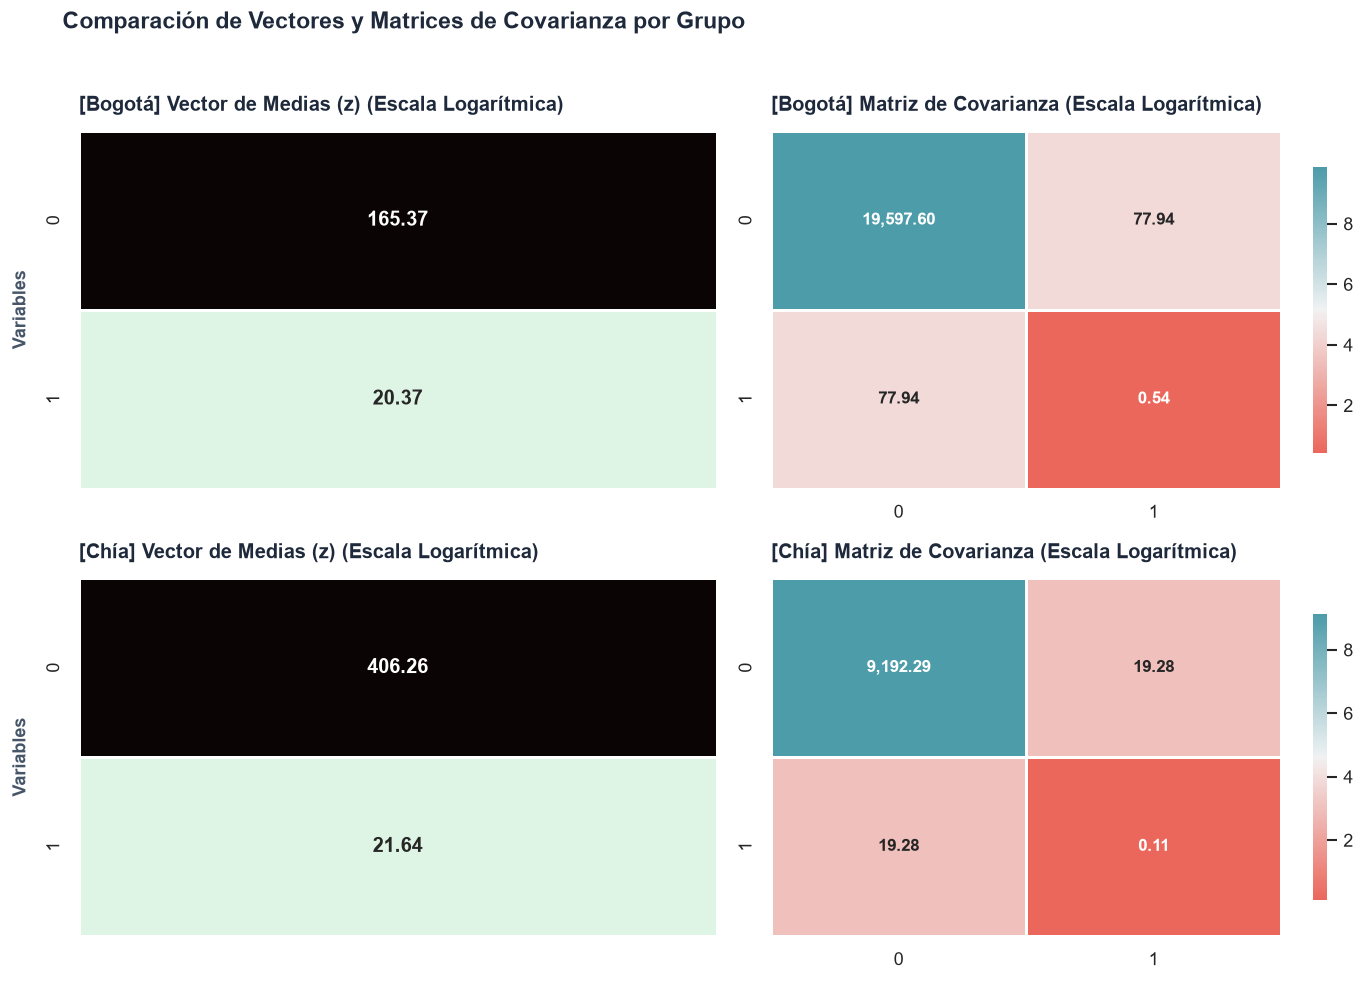

In [184]:
resultados_dict = {
    'Bogotá': [resultados_1['z_1'], resultados_1['cov1']],
    'Chía': [resultados_1['z_2'], resultados_1['cov2']]
}

# Llamada a la función
plot_groups_heatmap(resultados_dict, log_scale=True)

In [190]:
# diferencia entre precios en escala original

precios_log_bog = resultados_1['z_1'][1]
precios_log_chia = resultados_1['z_2'][1]

print(f"Precios en escala log\n Bogota {precios_log_bog}\n  Chia {precios_log_chia}")
print(f"Precios en escala original\n Bogota {np.exp(precios_log_bog):,.2f}\n  Chia {np.exp(precios_log_chia):,.2f}")

Precios en escala log
 Bogota 20.367406467557707
  Chia 21.63971404424168
Precios en escala original
 Bogota 700,571,135.05
  Chia 2,500,393,719.55


Vea como la primera componente de los vectores de medias difiere en buena medida entre chia y bogota, esto da un primer indicio de rechazo de la prueba, asimismo en la segunda componente los precios parecen no cambiar mucho, no obstante recuerde que estan en elscala logaritmica y en la escala original la diferencia es realmente amplia (aparece en la celda que esta justo arriba).

Note ademas que las matrices de covarianzas no son iguales o si quiera similares de grupo a grupo, por lo que las conclusiones que acontinuacion se exponen corresponden a aquellas extraidas con la matriz $S_{diff}$ que se planteo al principio de la seccion (esos valores son aquellos con sufijo `_diff` en el diccionario). Dicho eso el p valor de la prueba fue 0, por lo tanto a un nivel de  confianza del 95% se rechaza la hipotesis nula y por lo tanto se conclute que los 2 vectores de medias son estadisticamente diferentes.

En el contexto esto implica que el comportamiento entre chia y bogota difiere de manera significativa, lo cual desemboca en el potecial planteamento de estrategias de compra venta diferentes segun la zona, pues esa diferencia podria generar que publicos diferentes sean los interesados en cada una de las ciudades (municipio en el caso de chia).

#### Viviendas de Bogotá v.s viviendas de Zipa

In [192]:
df_zipa = df[df['city'] == 'Zipaquirá'].copy()

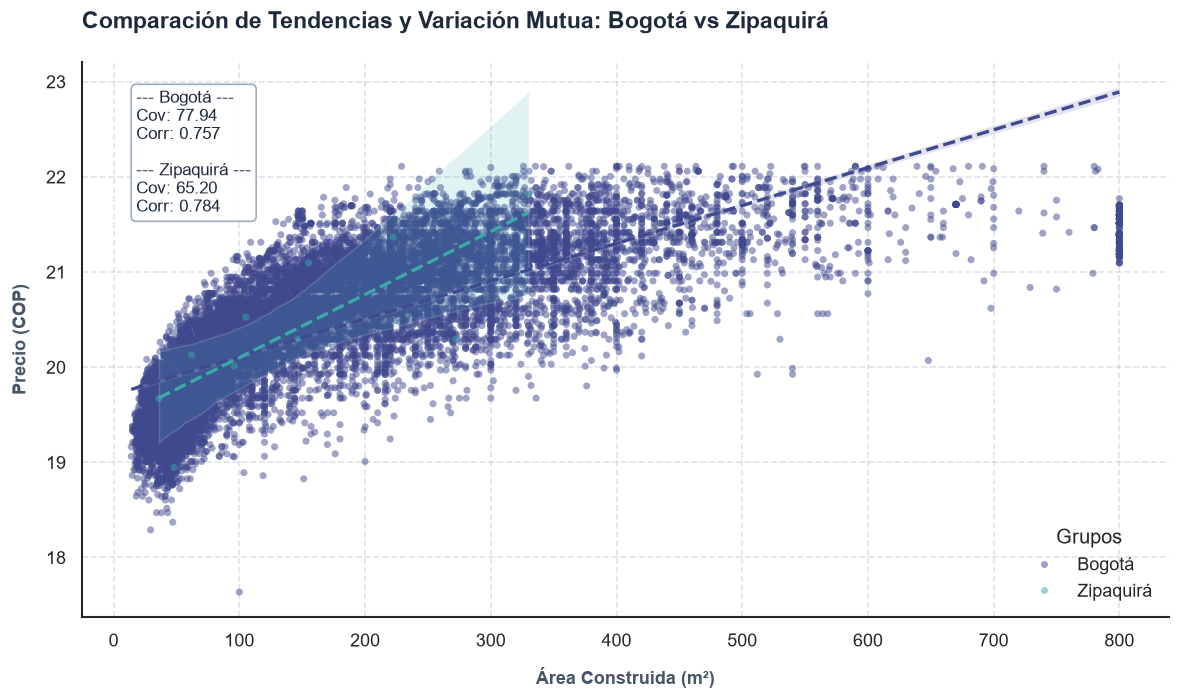

In [193]:
plot_group_comparison(df_bogota, df_zipa, label1='Bogotá', label2='Zipaquirá')

In [195]:
resultados_2 = hotteling_comparison(df_bogota, df_zipa, 'area_built_m2', 'log_price_amount')
resultados_2

{'z_1': array([165.37171486,  20.36740647]),
 'z_2': array([147.27674   ,  20.41351639]),
 'cov1': array([[1.95976037e+04, 7.79376490e+01],
        [7.79376490e+01, 5.40814868e-01]]),
 'cov2': array([[9.83831045e+03, 6.51965210e+01],
        [6.51965210e+01, 7.03434292e-01]]),
 'matriz de covarianzas comun': False,
 'S_diff': array([[9.84806293e+02, 6.52353056e+00],
        [6.52353056e+00, 7.03703421e-02]]),
 'S_pooled': array([[1.95932346e+04, 7.79319448e+01],
        [7.79319448e+01, 5.40887672e-01]]),
 'Z': array([18.09497486, -0.04610992]),
 'T2_diff': np.float64(1.3468448644727555),
 'F_stat_diff': np.float64(0.6733554383613045),
 'p_value_diff': np.float64(0.5100059513472209),
 'reject_null_diff': np.False_,
 'T2_pooled': np.float64(0.7705685788779268),
 'F_stat_pooled': np.float64(0.3852459603214307),
 'p_value_pooled': np.float64(0.6802883153967254),
 'reject_null_pooled': np.False_}

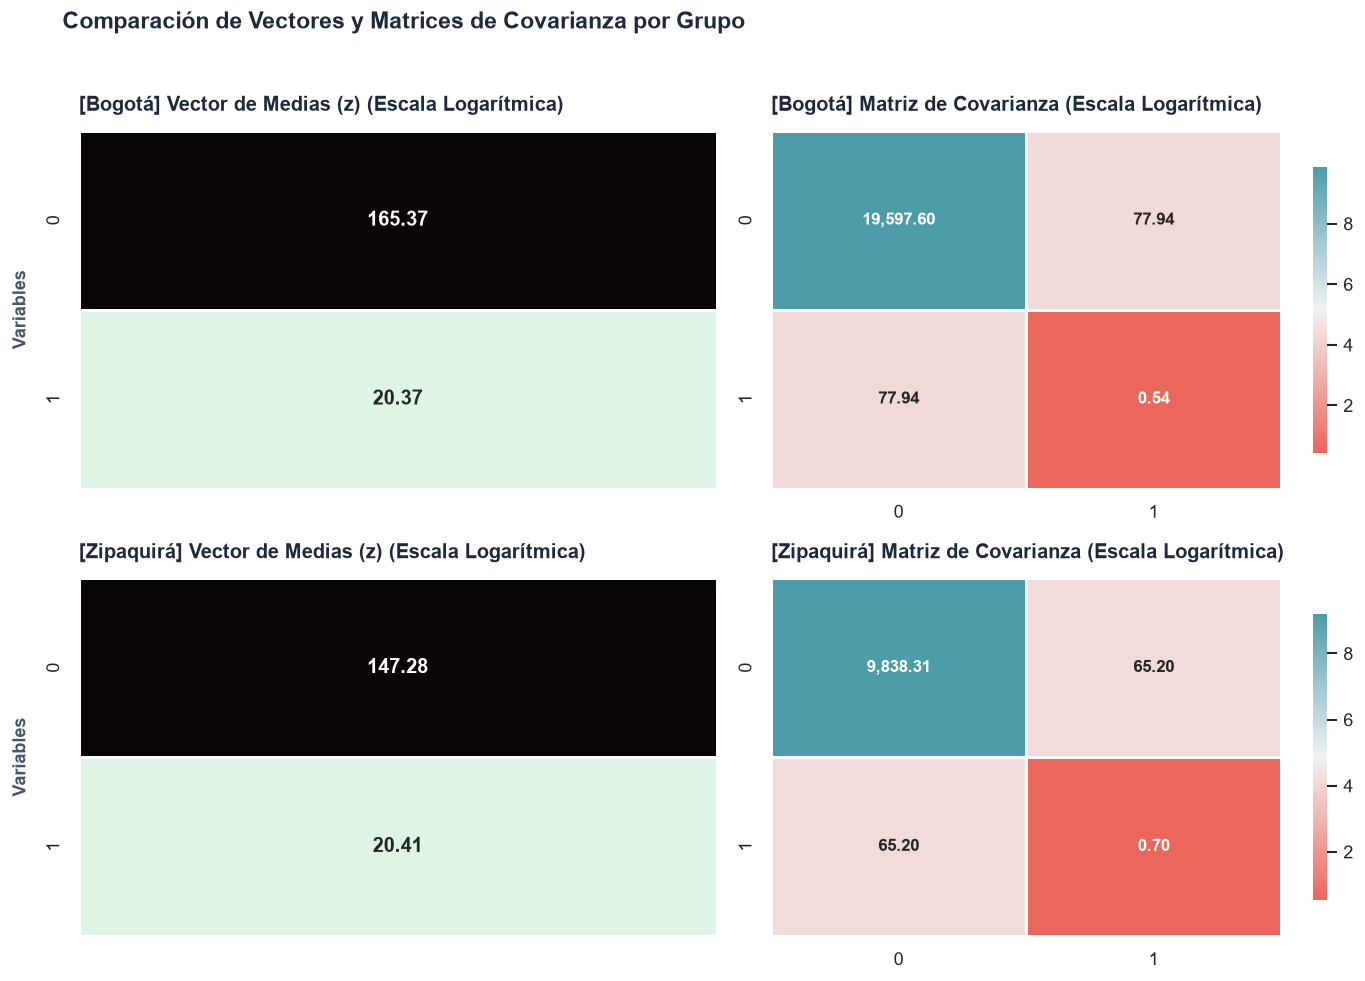

In [197]:
resultados_dict = {
    'Bogotá': [resultados_2['z_1'], resultados_2['cov1']],
    'Zipaquirá': [resultados_2['z_2'], resultados_2['cov2']]
}

# Llamada a la función
plot_groups_heatmap(resultados_dict, log_scale=True)

In [198]:
# diferencia entre precios en escala original

precios_log_bog = resultados_2['z_1'][1]
precios_log_zipa = resultados_2['z_2'][1]

print(f"Precios en escala log\n Bogota {precios_log_bog}\n  Zipa {precios_log_zipa}")
print(f"Precios en escala original\n Bogota {np.exp(precios_log_bog):,.2f}\n  Zipa {np.exp(precios_log_zipa):,.2f}")

Precios en escala log
 Bogota 20.367406467557707
  Zipa 20.41351639050789
Precios en escala original
 Bogota 700,571,135.05
  Zipa 733,630,747.00


In [204]:
df_zipa.shape[0], df_bogota.shape[0], df_chia.shape[0]

(10, 20095, 187)

En este caso la primera componente (que de nuevo corresponde al area construida) no tiene una diferencia tan grande como en la comparasion anterior, asimismo los precios (incluso en su escala real) no son especialmente diferentes entre si, esto da un buen primer indicio sobre el no rechazo de la prueba.

Puesto que las matrices de cov no se parecen en gran medida se utilizaran los calculos que corresponden al uso de la matriz $S_{diff}$, usando dicha matriz el p valor fue aproximadamente de **0.51**, por lo que a un 95% de confianza no hay evidencia estadistica sufuciente para rechazar la hipotesis nula, por lo tanto no es posible afirmar que los vectores difieren entre si (recuerde que eso no hace que el hecho de que los 2 vectores de medias sean iguales cierto).

Bajo el contexto inmoviliario implica que las viviendas de Bogota y Zipa se tienen caracteristicas de precio y area construida similares, por lo que se les puede ofrecer a perfiles de clientes similares.

> Nota: Estas conclusiones se deben tomar con cautela pues la cantidad de datos sobre Zipa es minuscula frente a los datos que se tienen sobre Bogota, especificamente 10 vs 20095, por lo que estas conclusiones no son del todo confiables y se tienen que estimar sobre un conjunto con mayor representatividad del municipio, esto se escogio principalmente por la similitud inicial que se vio entre las zonas y para ejemplificar una prueba que no se rechaza.

#### Viviendas de Bogotá v.s viviendas de Soacha

In [205]:
df_soa = df[df['city'] == 'Soacha'].copy()

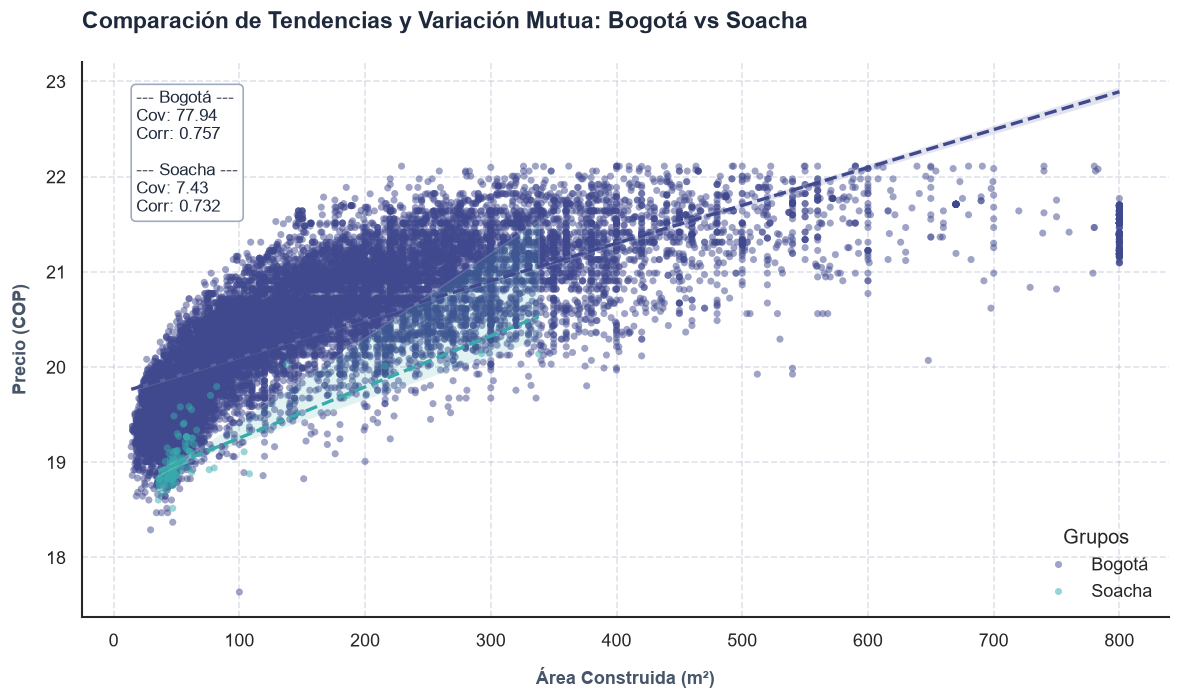

In [206]:
plot_group_comparison(df_bogota, df_soa, label1='Bogotá', label2='Soacha')

In [207]:
resultados_3 = hotteling_comparison(df_bogota, df_soa, 'area_built_m2', 'log_price_amount')
resultados_3

{'z_1': array([165.37171486,  20.36740647]),
 'z_2': array([56.09481333, 19.01876982]),
 'cov1': array([[1.95976037e+04, 7.79376490e+01],
        [7.79376490e+01, 5.40814868e-01]]),
 'cov2': array([[1.38575438e+03, 7.42782896e+00],
        [7.42782896e+00, 7.44049855e-02]]),
 'matriz de covarianzas comun': False,
 'S_diff': array([[1.02136103e+01, 5.33973195e-02],
        [5.33973195e-02, 5.22946144e-04]]),
 'S_pooled': array([[1.94635542e+04, 7.74186566e+01],
        [7.74186566e+01, 5.37381826e-01]]),
 'Z': array([109.27690153,   1.34863665]),
 'T2_diff': np.float64(3647.791419180609),
 'F_stat_diff': np.float64(1823.7155183524474),
 'p_value_diff': np.float64(0.0),
 'reject_null_diff': np.True_,
 'T2_pooled': np.float64(633.4244820266085),
 'F_stat_pooled': np.float64(316.6809515210089),
 'p_value_pooled': np.float64(3.7585503902509665e-136),
 'reject_null_pooled': np.True_}

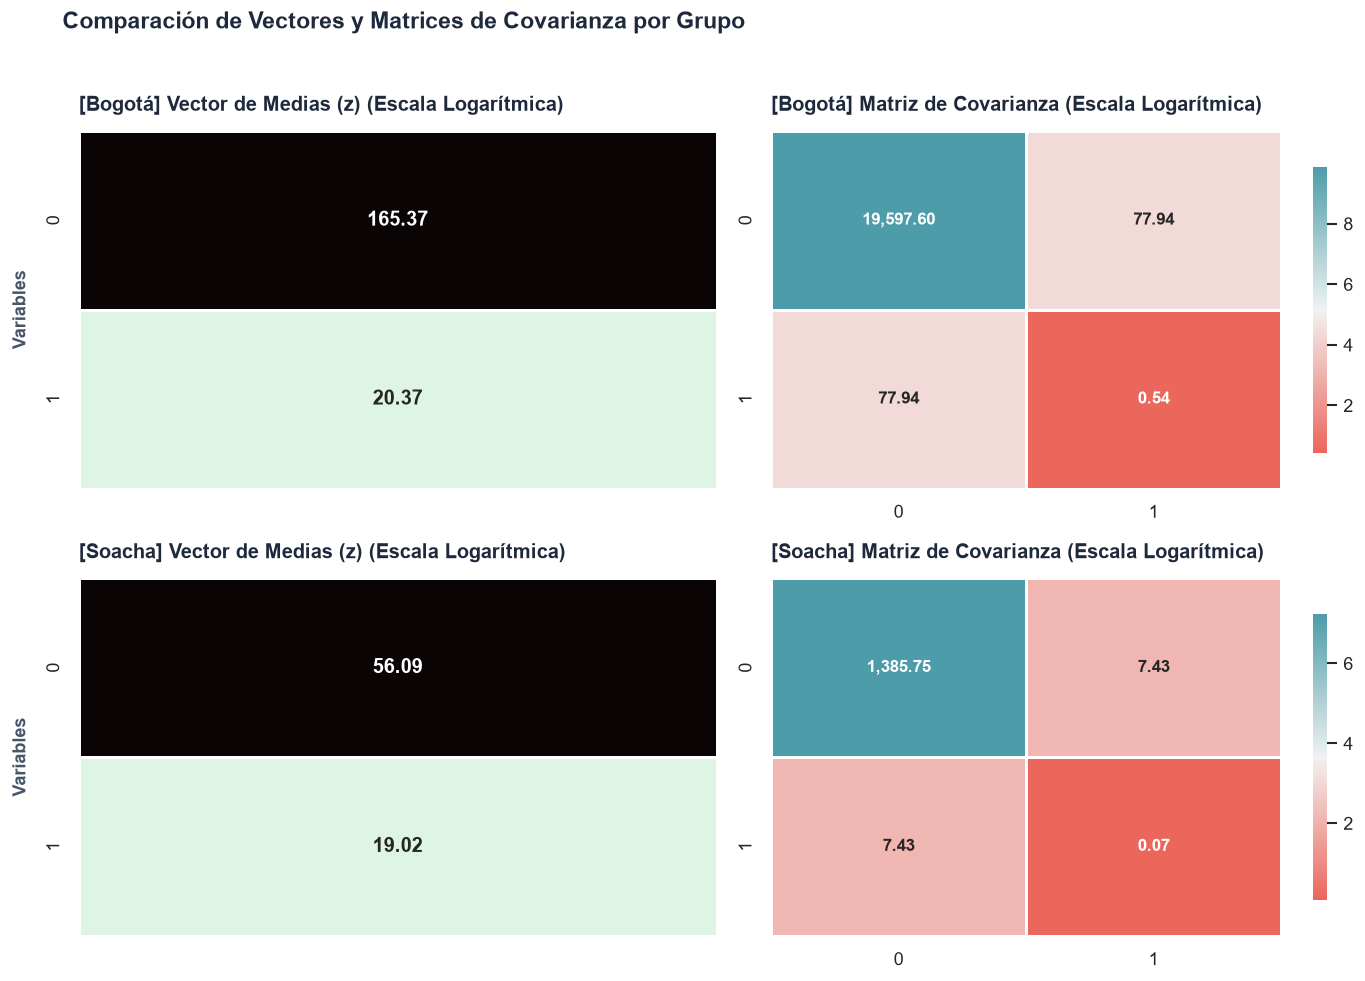

In [210]:
resultados_dict = {
    'Bogotá': [resultados_3['z_1'], resultados_3['cov1']],
    'Soacha': [resultados_3['z_2'], resultados_3['cov2']]
}

# Llamada a la función
plot_groups_heatmap(resultados_dict, log_scale=True)

In [214]:
# diferencia entre precios en escala original

precios_log_bog = resultados_3['z_1'][1]
precios_log_soa = resultados_3['z_2'][1]

print(f"Precios en escala log\n Bogota {precios_log_bog}\n  Soacha {precios_log_soa}")
print(f"Precios en escala original\n Bogota {np.exp(precios_log_bog):,.2f}\n  Soacha {np.exp(precios_log_soa):,.2f}")

Precios en escala log
 Bogota 20.367406467557707
  Soacha 19.018769817243864
Precios en escala original
 Bogota 700,571,135.05
  Soacha 181,864,018.97


Para este caso la diferencia entre las areas construidas es amplia, siendo menor en Soacha, y lo mismo ocurre con el precio, hay una diferencia realmente alta donde Soacha es la que menores precios tiene en promedio, esto es un primer indicio de que la prueba sera rechazada.

Puesto que las matrices de cov son diferentes entre si se opta por basarse en las conclusiones extraidas de $S_{diff}$. Donde el p valor es de **0.0**, por lo que a un 95% de confianza se rechaza la hipotesis nula y por lo tanto hay sufuciente evidencia para afirmar que los vecotres de medias de las dos zonas son estadisticamente diferentes.

En el contexto inmoviliario indica que se pueden ofrecer las viviendas de Soacha a clientes que busquen opciones mas asequibles que las que hay en los otros municipios o en Bogota.

### ¿Porque el procedimiento es analogo a la comparasión entre medias?

#### Cuando se asumen las varianzas iguales.

Se toma la variabilidad ponderada como $$S_p^2 = \frac{(n_1 - 1)S_1^2 + (n_2 - 1)S_2^2}{n_1 + n_2 - 2}$$

y el estadistico t se calcula de la siguiente forma:

$$t = \frac{(\bar{x}_1 - \bar{x}_2) - (\mu_1 - \mu_2)}{S_p \sqrt{\frac{1}{n_1} + \frac{1}{n_2}}}$$

pero en forma cuadrada que es con aquella que la anlogia es mas clara es:

$$t^2 = \frac{(\bar{x}_1 - \bar{x}_2)^2}{S_p^2 \left(\frac{1}{n_1} + \frac{1}{n_2}\right)}$$

Vea que los calculos son iguales solo que generalizados a matrices, si bien la formula de $S_p^2$, no es muy diferente la comparacion interesante reside en el calculo de los estadisticos en si mismos, pues se tiene que 

$$T^2 = (\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2)^\top \left[ S_p \left( \frac{1}{n_1} + \frac{1}{n_2} \right) \right]^{-1} (\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2)$$

donde el termino $[S_p ( \frac{1}{n_1} + \frac{1}{n_2})]^{-1}$ es analogo a el denominador del calculo del estadistico t, pues en el mundo matricial la inversa de una matriz tiene el mismo efecto que utilizar un numero para dividir, ademas los terminos $(\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2)^\top ... \space (\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2)$ Son analogos a la diferencia $\bar{x}_1 - \bar{x}_2$, solo que en este caso 'elevada al cuadrado'.

El termino $[S_p ( \frac{1}{n_1} + \frac{1}{n_2})]^{-1}$ esta en el centro pues es la forma que valida la multiplicacion de matrices, esto por las dimensiones y permite que el resultado final sea un escalar.

## 6. Analisis Adicional.

Se plantea un nuevo analisis sobre grupos en esta oportunidad comparando las localidades que comunmente se perciben como norte contra las que se perciben como sur (Se habla de percepcion pues no es tan claro en aquellas localidades al occidente de la ciudad). En esta oportunidad se comparan mas de 2 variables y se seleccionan las siguientes:

- `log_price_amount`
- `area_built_m2`
- `admin_fee`

In [219]:
# 1. Fusionar variantes sin tilde con su versión con tilde
df['locality'] = df['locality'].replace({
    'Engativa': 'Engativá',
    'Fontibon': 'Fontibón',
})

# 2. Listas finales (ya sin duplicados)
norte = [
    'Usaquen',
    'Chapinero',
    'Suba',
    'Barrios Unidos',
    'Teusaquillo',
    'Engativá',
    'Fontibón',
]

sur = [
    'Kennedy',
    'Rafael Uribe',
    'Tunjuelito',
    'Puente Aranda',
    'Ciudad Bolivar',
    'Santafe',
    'San Cristobal',
    'Antonio Nariño',
    'Bosa',
    'LA Candelaria',
    'Los Martires',
    'Usme',
]

# Columna booleana: True si la localidad es del norte, False si es del sur
df['norte'] = df['locality'].isin(norte)

df_bogota = df[df['city'] == 'Bogotá']

df_norte = df_bogota[df_bogota['norte']].copy()
df_sur = df_bogota[~df_bogota['norte']].copy()


<Axes: title={'left': 'Distribución de Norte'}, xlabel='Norte', ylabel='Conteo'>

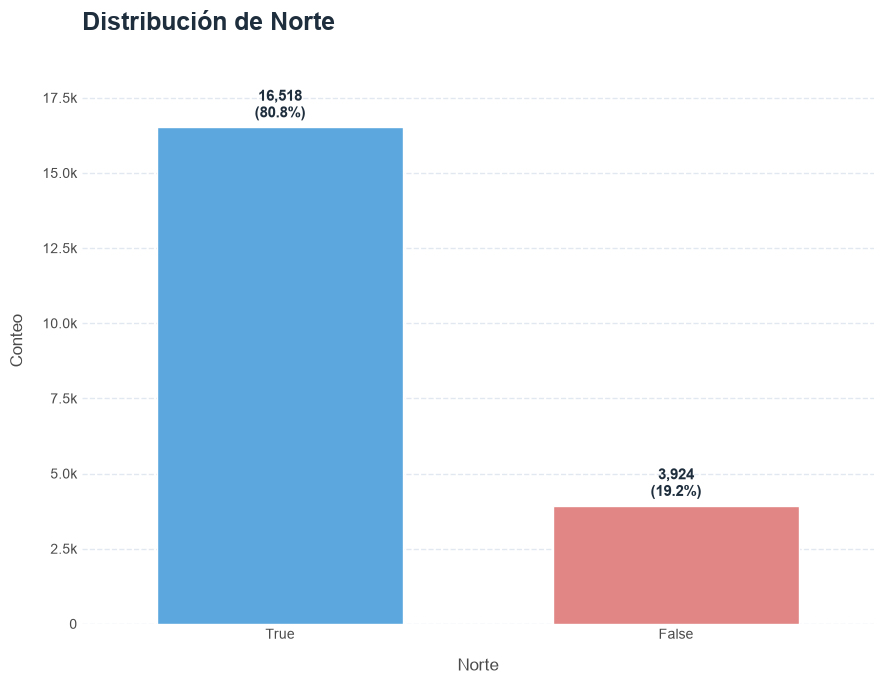

In [223]:
fancy_bars(df, x='norte', labels='both')

Se hace evitente la desproporcion entre los inmuebles norte que se tienen y los que estan al sur, eso aunque se consideren mas localidades como sur, sin embargo esto no tiene que ser un problema para esta prueba, pues ambos grupos son lo suficientemente grandes. El unico problema que podria ocurrir es una baja representatividad del sur que sera mucho mas dificil de daignosticar sin conocer la poblacion, por lo tanto se asumira que ambas muestras son representativas.

In [224]:
numeric_vars = ['log_price_amount', 'area_built_m2', 'admin_fee']

In [228]:
resultados = []
for num_var in numeric_vars:
    res = hub_pruebas_num_cat(df, num_var, ["norte"])
    res = res.copy()
    res.insert(0, "variable", num_var)  # identifica de qué variable viene cada fila
    resultados.append(res)

df_resultados = pd.concat(resultados, ignore_index=True)
display(df_resultados)

,variable,var_numerica,var_categorica,n_grupos,prueba,estadistico,p_valor,normalidad,homocedasticidad,decision,conclusion,post_hoc
0,log_price_amount,log_price_amount,norte,2,U de Mann-Whitney,14492589.0,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,
1,area_built_m2,area_built_m2,norte,2,U de Mann-Whitney,22085948.5,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,
2,admin_fee,admin_fee,norte,2,U de Mann-Whitney,9278642.5,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,


Las pruebas respaldan que el factor de estar al norte si que hace que haya una dependencia con todas las varaibles, a continuacion se plasma de manera grafica.

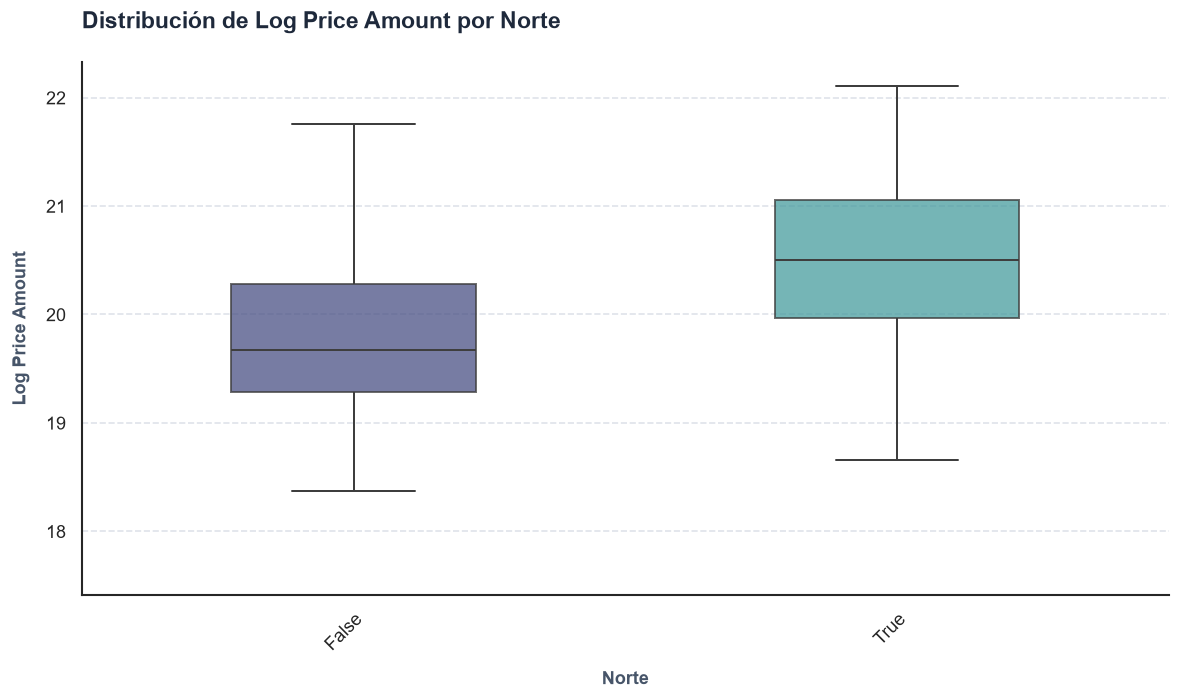

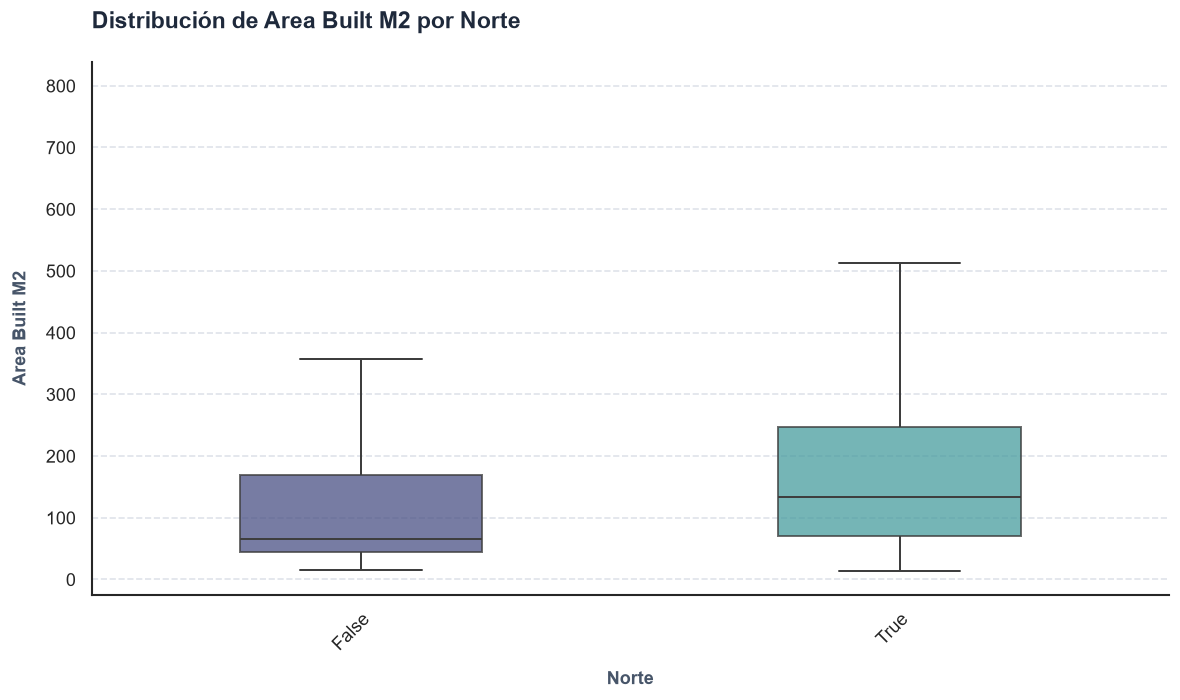

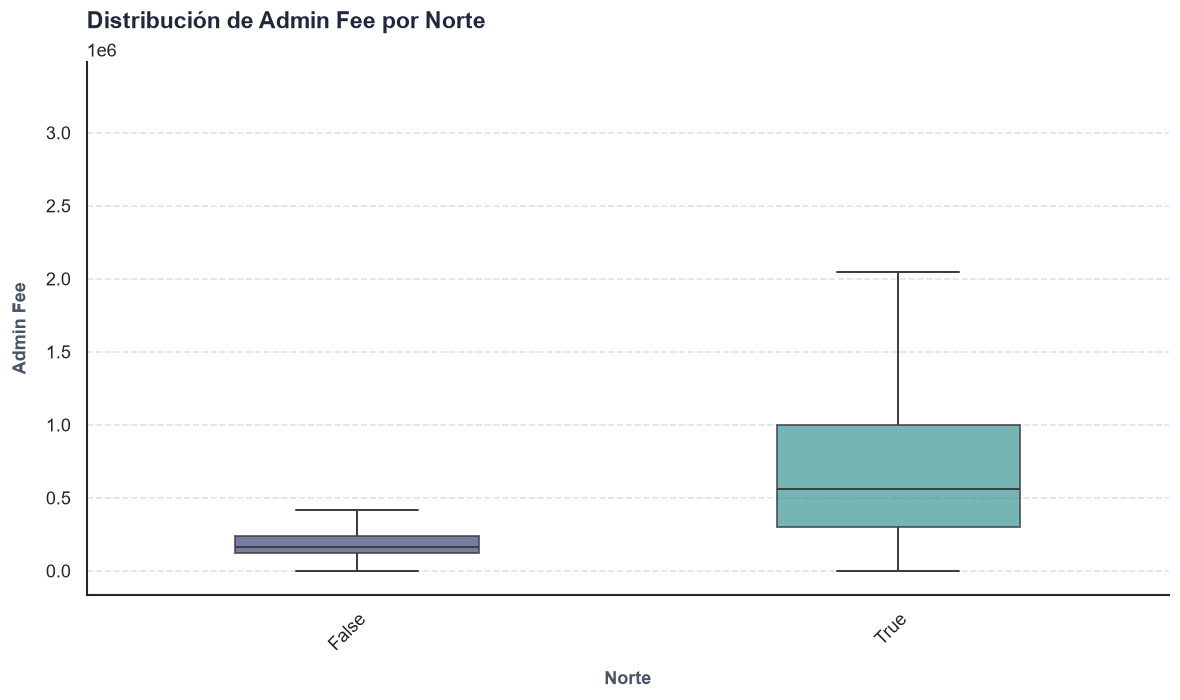

In [230]:
for num_var in numeric_vars:
    plot_segmented_boxplot(df, num_var, "norte", show_points=False)

La variable que muestra la diferencia mas marcada entre norte y sur es el precio, mientras que para las otras 2 la diferencias se ve principalmente que al sur las variables varian menos, tienden a tener un IQR mas estrecho y una mediana menor, aunque los bigotes inferiores no son especialmente distintos entre si. 

In [232]:
def hotteling_comparison_multivariate(df1, df2, cols, alpha=0.05):
    cols = list(cols)
    p = len(cols)  # número de variables (generaliza el caso bivariado)
    n1, n2 = len(df1), len(df2)

    z_1 = df1[cols].mean().to_numpy()
    z_2 = df2[cols].mean().to_numpy()

    cov1 = df1[cols].cov().to_numpy()
    cov2 = df2[cols].cov().to_numpy()

    cov_ig = np.allclose(cov1, cov2, rtol=1e-4, atol=1e-6)

    S_diff = cov1 / n1 + cov2 / n2
    S_pooled = ((n1 - 1) * cov1 + (n2 - 1) * cov2) / (n1 + n2 - 2)

    Z = z_1 - z_2

    # Covarianzas distintas
    T2_diff = Z.T @ np.linalg.inv(S_diff) @ Z
    F_stat_diff = ((n1 + n2 - p - 1) / (p * (n1 + n2 - 1))) * T2_diff
    p_value_diff = f.sf(F_stat_diff, dfn=p, dfd=n1 + n2 - p - 1)
    reject_null_diff = p_value_diff < alpha

    # Covarianza común (pooled)
    S_pooled_scaled = S_pooled * (1 / n1 + 1 / n2)
    T2_pooled = Z.T @ np.linalg.inv(S_pooled_scaled) @ Z
    F_stat_pooled = ((n1 + n2 - p - 1) / (p * (n1 + n2 - 1))) * T2_pooled
    p_value_pooled = f.sf(F_stat_pooled, dfn=p, dfd=n1 + n2 - p - 1)
    reject_null_pooled = p_value_pooled < alpha

    return {
        'z_1': z_1,
        'z_2': z_2,
        'cov1': cov1,
        'cov2': cov2,
        'matriz de covarianzas comun': cov_ig,
        'S_diff': S_diff,
        'S_pooled': S_pooled,
        'Z': Z,
        'T2_diff': T2_diff,
        'F_stat_diff': F_stat_diff,
        'p_value_diff': p_value_diff,
        'reject_null_diff': reject_null_diff,
        'T2_pooled': T2_pooled,
        'F_stat_pooled': F_stat_pooled,
        'p_value_pooled': p_value_pooled,
        'reject_null_pooled': reject_null_pooled,
    }

In [234]:
res_bonus = hotteling_comparison_multivariate(df_norte, df_sur, numeric_vars)
res_bonus

{'z_1': array([2.04963746e+01, 1.75680661e+02, 7.28359505e+05]),
 'z_2': array([1.98093083e+01, 1.20760653e+02, 2.42311507e+05]),
 'cov1': array([[4.92254392e-01, 7.71810303e+01, 2.48163740e+05],
        [7.71810303e+01, 2.07023796e+04, 2.72326270e+07],
        [2.48163740e+05, 2.72326270e+07, 3.32710008e+11]]),
 'cov2': array([[3.67590268e-01, 5.05743026e+01, 2.46836918e+04],
        [5.05743026e+01, 1.23703153e+04, 9.80043478e+04],
        [2.46836918e+04, 9.80043478e+04, 1.08130774e+11]]),
 'matriz de covarianzas comun': False,
 'S_diff': array([[1.27609454e-04, 1.81361821e-02, 2.17472436e+01],
        [1.81361821e-02, 4.54780597e+00, 1.69434125e+03],
        [2.17472436e+01, 1.69434125e+03, 4.90495908e+07]]),
 'S_pooled': array([[4.68857766e-01, 7.21875515e+01, 2.06221608e+05],
        [7.21875515e+01, 1.91386403e+04, 2.21400743e+07],
        [2.06221608e+05, 2.21400743e+07, 2.90561583e+11]]),
 'Z': array([6.87066236e-01, 5.49200083e+01, 4.86047998e+05]),
 'T2_diff': np.float64(721

In [236]:
numeric_vars

['log_price_amount', 'area_built_m2', 'admin_fee']

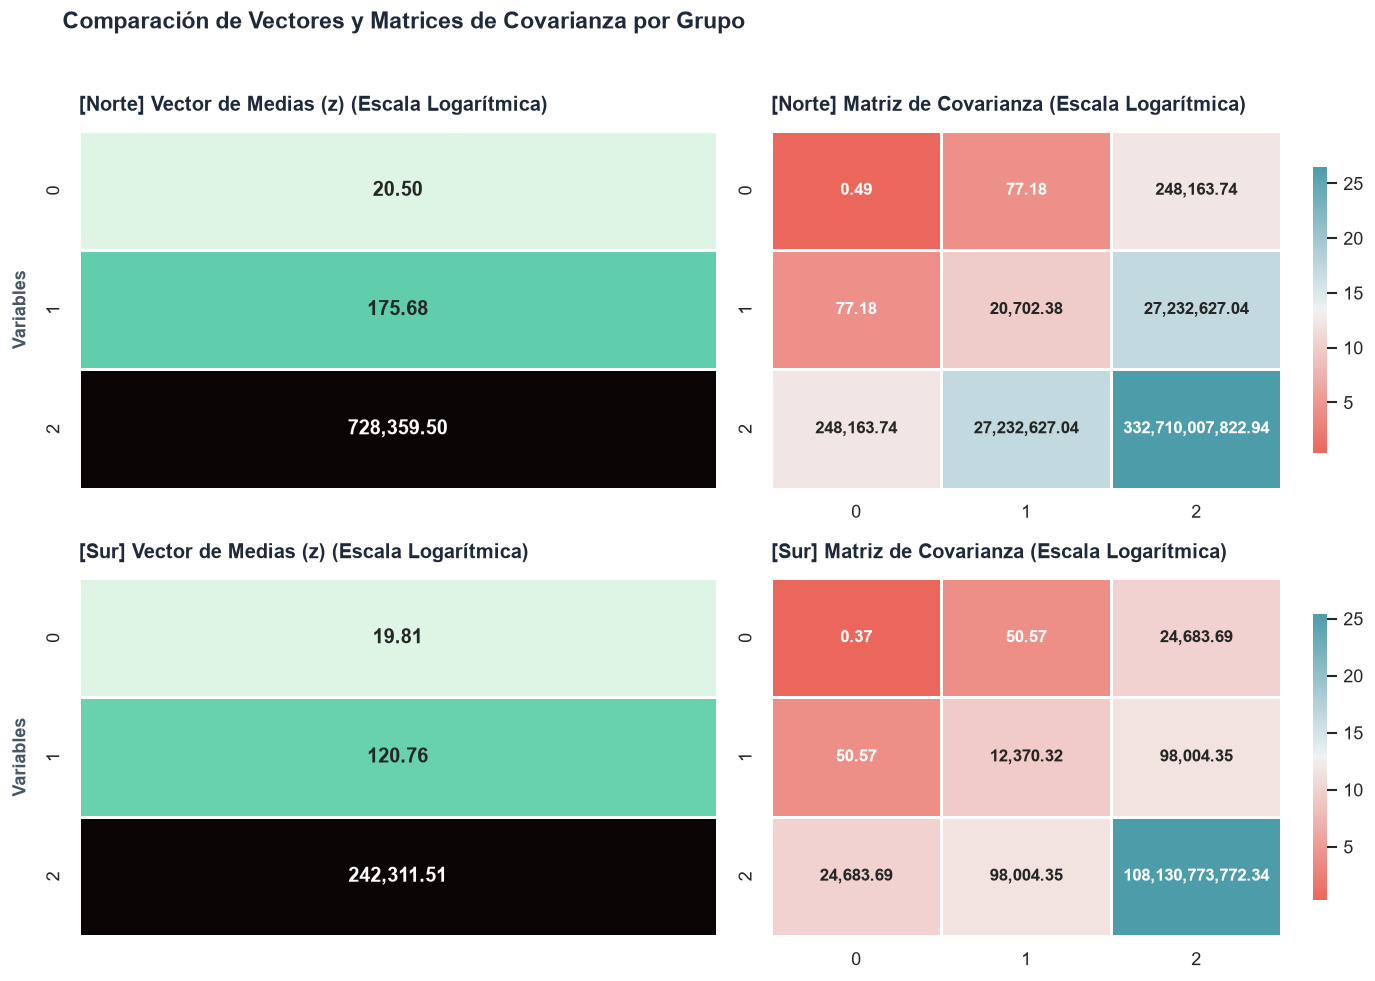

In [235]:
resultados_dict = {
    'Norte': [res_bonus['z_1'], res_bonus['cov1']],
    'Sur': [res_bonus['z_2'], res_bonus['cov2']]
}

# Llamada a la función
plot_groups_heatmap(resultados_dict, log_scale=True)

In [243]:
# diferencia entre precios en escala original

precios_log_norte = res_bonus['z_1'][0]
precios_log_sur = res_bonus['z_2'][0]

print(f"Precios en escala log\n  Norte {precios_log_norte}\n  Sur {precios_log_sur}")
print(f"Precios en escala original\n  Norte {np.exp(precios_log_norte):,.2f}\n  Sur {np.exp(precios_log_sur):,.2f}")

Precios en escala log
  Norte 20.49637456116616
  Sur 19.80930832546577
Precios en escala original
  Norte 797,007,431.59
  Sur 400,934,377.79


Solo viendo el vector de medias se puede apreciar como todas las variables consideradas tienen una  diferencia amplia entre norte y sur, siendo las mas drasticas el precio y la administracion, no obstante el area construida tambien presenta una diferencia considerable, esto es el primer indicio (junto a las preuebas y evidencias graficas mostradas anteriormente) de que se rechazara la hipotesis nula.

Dado que las matrices de cov son realmente distintas entre si se opta por utilizar las conclusiones obtenidas mediante $S_{diff}$, dicho esto el valor p utilizando ese metodo es de **0.0** lo cual constituye un claro rechazo a la hipotesis nula a un 95% de confianza, por lo tanto hay evidencia suficiente para afirmar que los vectores de medias difieren entre si (esto considerando la asociacion entre variables gracias a la distancia de mahalanobis, detalle que se obvio en oportunidades anteriores).

En el contexto eso indica que los inmuebles que estan en el norte y los que estan en el sur son estadisticamente diferentes entre si en muchas de las caracteristicas fisicas clave de estos, lo cual a su vez posiblemente indique que los cliente que se interezan en cada sector de la ciudad sean radicalmente diferentes.